In [43]:
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler, MinMaxScaler, LabelEncoder
from sklearn.linear_model import LogisticRegression, LinearRegression, Ridge, Lasso
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor
from sklearn.svm import SVC, SVR
from sklearn.neighbors import KNeighborsClassifier, KNeighborsRegressor
from sklearn.ensemble import RandomForestRegressor,AdaBoostRegressor

# Data handling and visualization
import matplotlib.pyplot as plt

# Data preparation and pipelines

# Train/validation splitting and model selection
from sklearn.model_selection import (
    train_test_split,
    cross_val_score,
    GridSearchCV,
    RandomizedSearchCV,
)

# Common models
from sklearn.ensemble import (
    RandomForestClassifier,
    RandomForestRegressor,
    GradientBoostingClassifier,
    GradientBoostingRegressor,
    AdaBoostRegressor
)

# Evaluation metrics
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    roc_auc_score,
    mean_absolute_error,
    mean_squared_error,
    r2_score,
)

from catboost import CatBoostRegressor
from xgboost import XGBRegressor

In [62]:
df=pd.read_csv('data/data.csv')
df.head()

,Cement,Blast Furnace Slag,Fly Ash,Water,Superplasticizer,Coarse Aggregate,Fine Aggregate,Age,Strength
0,540.0,0.0,0.0,162.0,2.5,1040.0,676.0,28,79.99
1,540.0,0.0,0.0,162.0,2.5,1055.0,676.0,28,61.89
2,332.5,142.5,0.0,228.0,0.0,932.0,594.0,270,40.27
3,332.5,142.5,0.0,228.0,0.0,932.0,594.0,365,41.05
4,198.6,132.4,0.0,192.0,0.0,978.4,825.5,360,44.30


In [63]:
df.drop_duplicates(inplace=True)

In [64]:
df.info()

<class 'pandas.DataFrame'>
Index: 1005 entries, 0 to 1029
Data columns (total 9 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Cement              1005 non-null   float64
 1   Blast Furnace Slag  1005 non-null   float64
 2   Fly Ash             1005 non-null   float64
 3   Water               1005 non-null   float64
 4   Superplasticizer    1005 non-null   float64
 5   Coarse Aggregate    1005 non-null   float64
 6   Fine Aggregate      1005 non-null   float64
 7   Age                 1005 non-null   int64  
 8   Strength            1005 non-null   float64
dtypes: float64(8), int64(1)
memory usage: 78.5 KB


In [23]:
df.describe()

,Cement,Blast Furnace Slag,Fly Ash,Water,Superplasticizer,Coarse Aggregate,Fine Aggregate,Age,Strength
count,1005.000000,1005.000000,1005.000000,1005.000000,1005.000000,1005.000000,1005.000000,1005.000000,1005.000000
mean,278.631343,72.043483,55.536318,182.075323,6.033234,974.376816,772.688259,45.856716,35.250378
std,104.344261,86.170807,64.207969,21.339334,5.919967,77.579667,80.340435,63.734692,16.284815
min,102.000000,0.000000,0.000000,121.800000,0.000000,801.000000,594.000000,1.000000,2.330000
25%,190.700000,0.000000,0.000000,166.600000,0.000000,932.000000,724.300000,7.000000,23.520000
50%,265.000000,20.000000,0.000000,185.700000,6.100000,968.000000,780.000000,28.000000,33.800000
75%,349.000000,142.500000,118.300000,192.900000,10.000000,1031.000000,822.200000,56.000000,44.870000
max,540.000000,359.400000,200.100000,247.000000,32.200000,1145.000000,992.600000,365.000000,82.600000


In [65]:
# Number of zero values in each column
zero_counts = df.eq(0).sum()
print(zero_counts)

# Total number of zero values in the dataframe
print("Total zero values:", df.eq(0).sum().sum())

Cement                  0
Blast Furnace Slag    470
Fly Ash               541
Water                   0
Superplasticizer      378
Coarse Aggregate        0
Fine Aggregate          0
Age                     0
Strength                0
dtype: int64
Total zero values: 1389


In [66]:
x=df.drop('Strength',axis=1)
x
y=df['Strength']

In [67]:
from sklearn.feature_selection import mutual_info_regression
from sklearn.feature_selection import SelectKBest
fs=SelectKBest(score_func=mutual_info_regression,k=3)
fs.fit(x,y)
mi_scores = pd.Series(fs.scores_, index=x.columns)
mi_scores.sort_values(ascending=False, inplace=True)

In [27]:
mi_scores

Age                   0.316535
Water                 0.275908
Cement                0.233325
Coarse Aggregate      0.182866
Superplasticizer      0.140958
Fine Aggregate        0.136815
Fly Ash               0.109758
Blast Furnace Slag    0.109214
dtype: float64

In [68]:
from sklearn.feature_selection import VarianceThreshold
selector=VarianceThreshold(threshold=0)
X_new=selector.fit_transform(x)
X_new=pd.DataFrame(X_new,columns=selector.get_feature_names_out())
X_new

,Cement,Blast Furnace Slag,Fly Ash,Water,Superplasticizer,Coarse Aggregate,Fine Aggregate,Age
0,540.0,0.0,0.0,162.0,2.5,1040.0,676.0,28.0
1,540.0,0.0,0.0,162.0,2.5,1055.0,676.0,28.0
2,332.5,142.5,0.0,228.0,0.0,932.0,594.0,270.0
3,332.5,142.5,0.0,228.0,0.0,932.0,594.0,365.0
4,198.6,132.4,0.0,192.0,0.0,978.4,825.5,360.0
...,...,...,...,...,...,...,...,...
1000,276.4,116.0,90.3,179.6,8.9,870.1,768.3,28.0
1001,322.2,0.0,115.6,196.0,10.4,817.9,813.4,28.0
1002,148.5,139.4,108.6,192.7,6.1,892.4,780.0,28.0
1003,159.1,186.7,0.0,175.6,11.3,989.6,788.9,28.0


In [69]:
# Variance of each column in the feature DataFrame
column_variances = X_new.var()
print(column_variances)

Cement                10887.724744
Blast Furnace Slag     7425.407978
Fly Ash                4122.663231
Water                   455.367179
Superplasticizer         35.046006
Coarse Aggregate       6018.604691
Fine Aggregate         6454.585440
Age                    4062.110923
dtype: float64


In [70]:
correlations = df.corr(numeric_only=True)["Strength"].drop("Strength").sort_values(ascending=False)
print(correlations)

Cement                0.488283
Superplasticizer      0.344209
Age                   0.337367
Blast Furnace Slag    0.103374
Fly Ash              -0.080648
Coarse Aggregate     -0.144717
Fine Aggregate       -0.186448
Water                -0.269624
Name: Strength, dtype: float64


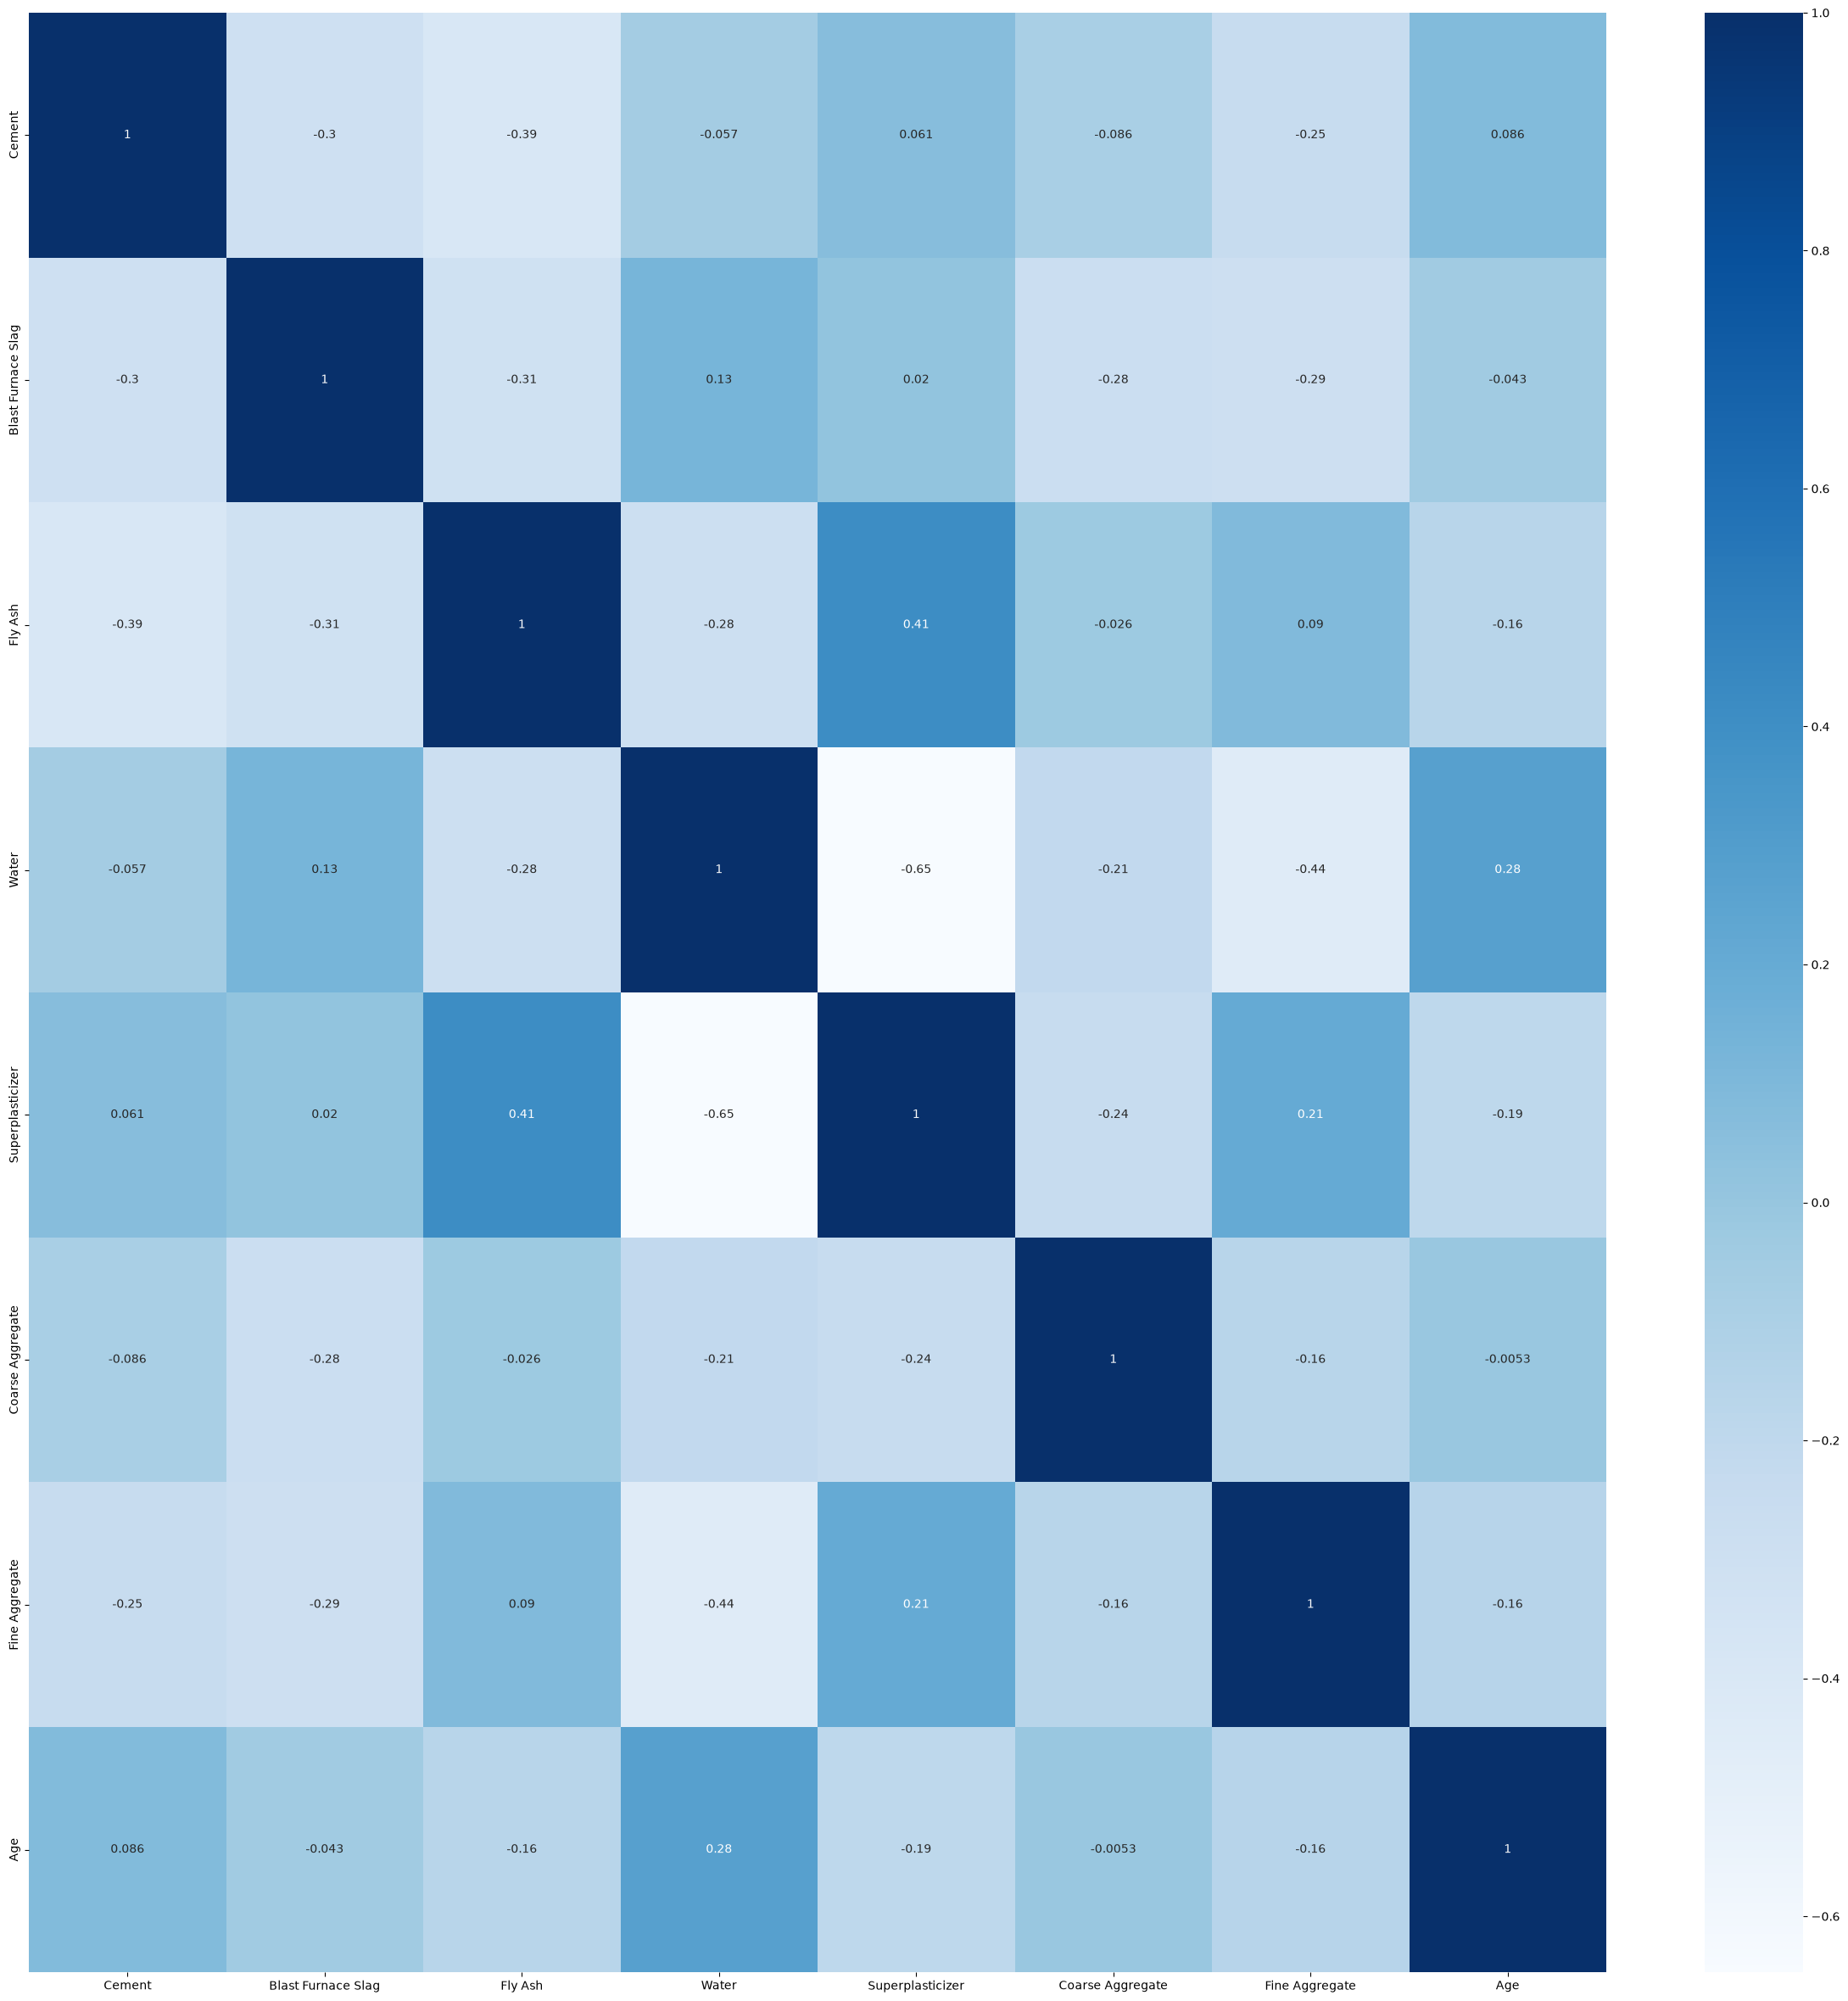

In [71]:
plt.figure(figsize=(30,30))
sns.heatmap(X_new.corr(),annot=True,cmap='Blues')
plt.show()

In [72]:
x=x.drop(['Fly Ash','Blast Furnace Slag'],axis=1)
x

,Cement,Water,Superplasticizer,Coarse Aggregate,Fine Aggregate,Age
0,540.0,162.0,2.5,1040.0,676.0,28
1,540.0,162.0,2.5,1055.0,676.0,28
2,332.5,228.0,0.0,932.0,594.0,270
3,332.5,228.0,0.0,932.0,594.0,365
4,198.6,192.0,0.0,978.4,825.5,360
...,...,...,...,...,...,...
1025,276.4,179.6,8.9,870.1,768.3,28
1026,322.2,196.0,10.4,817.9,813.4,28
1027,148.5,192.7,6.1,892.4,780.0,28
1028,159.1,175.6,11.3,989.6,788.9,28


In [73]:
y=df['Strength']



In [74]:
y.shape

(1005,)

In [75]:
x.shape

(1005, 6)

### Model Training

In [76]:
X_train, X_test, y_train, y_test = train_test_split(x,y,test_size=0.2,random_state=42)

In [77]:
print("X_train:", X_train.shape)
print("y_train:", y_train.shape)

print("X_test:", X_test.shape)
print("y_test:", y_test.shape)

X_train: (804, 6)
y_train: (804,)
X_test: (201, 6)
y_test: (201,)


In [78]:
def evaluate_model(true,predicted):

    mae=mean_absolute_error(true,predicted)
    mse=mean_squared_error(true,predicted)
    rmse=np.sqrt(mse)
    r2=r2_score(true,predicted)
    return mae,rmse,r2


In [79]:
models = {
    "Linear Regression": LinearRegression(),
    "Lasso": Lasso(),
    "Ridge": Ridge(),
    "K-Neighbors Regressor": KNeighborsRegressor(),
    "Decision Tree": DecisionTreeRegressor(),
    "Random Forest Regressor": RandomForestRegressor(),
    "XGBRegressor": XGBRegressor(), 
    "CatBoosting Regressor": CatBoostRegressor(verbose=False),
    "AdaBoost Regressor": AdaBoostRegressor()
}
model_list = []
r2_list =[]

for i in range(len(list(models))):
    model = list(models.values())[i]
    model.fit(X_train, y_train) # Train model

    # Make predictions
    y_train_pred = model.predict(X_train)
    y_test_pred = model.predict(X_test)
    
    # Evaluate Train and Test dataset
    model_train_mae , model_train_rmse, model_train_r2 = evaluate_model(y_train, y_train_pred)

    model_test_mae , model_test_rmse, model_test_r2 = evaluate_model(y_test, y_test_pred)

    
    print(list(models.keys())[i])
    model_list.append(list(models.keys())[i])
    
    print('Model performance for Training set')
    print("- Root Mean Squared Error: {:.4f}".format(model_train_rmse))
    print("- Mean Absolute Error: {:.4f}".format(model_train_mae))
    print("- R2 Score: {:.4f}".format(model_train_r2))

    print('----------------------------------')
    
    print('Model performance for Test set')
    print("- Root Mean Squared Error: {:.4f}".format(model_test_rmse))
    print("- Mean Absolute Error: {:.4f}".format(model_test_mae))
    print("- R2 Score: {:.4f}".format(model_test_r2))
    r2_list.append(model_test_r2)
    
    print('='*35)
    print('\n')

Linear Regression
Model performance for Training set
- Root Mean Squared Error: 10.5278
- Mean Absolute Error: 8.4559
- R2 Score: 0.5678
----------------------------------
Model performance for Test set
- Root Mean Squared Error: 11.7347
- Mean Absolute Error: 9.0679
- R2 Score: 0.5384


Lasso
Model performance for Training set
- Root Mean Squared Error: 10.5299
- Mean Absolute Error: 8.4567
- R2 Score: 0.5676
----------------------------------
Model performance for Test set
- Root Mean Squared Error: 11.7335
- Mean Absolute Error: 9.0756
- R2 Score: 0.5385


Ridge
Model performance for Training set
- Root Mean Squared Error: 10.5278
- Mean Absolute Error: 8.4559
- R2 Score: 0.5678
----------------------------------
Model performance for Test set
- Root Mean Squared Error: 11.7347
- Mean Absolute Error: 9.0679
- R2 Score: 0.5384


K-Neighbors Regressor
Model performance for Training set
- Root Mean Squared Error: 7.7153
- Mean Absolute Error: 5.8685
- R2 Score: 0.7679
-----------------

In [80]:
pd.DataFrame(list(zip(model_list, r2_list)), columns=['Model Name', 'R2_Score']).sort_values(by=["R2_Score"],ascending=False)

,Model Name,R2_Score
6,XGBRegressor,0.923230
7,CatBoosting Regressor,0.920349
5,Random Forest Regressor,0.889398
4,Decision Tree,0.846573
8,AdaBoost Regressor,0.760064
3,K-Neighbors Regressor,0.654090
1,Lasso,0.538509
0,Linear Regression,0.538409
2,Ridge,0.538409


In [81]:
XGB = XGBRegressor(fit_intercept=True)
XGB = XGB.fit(X_train, y_train)
y_pred = XGB.predict(X_test)
score = r2_score(y_test, y_pred)*100
print(" Accuracy of the model is %.2f" %score)

e:\Nisal\mlOP\Project 1\venv\Lib\site-packages\xgboost\training.py:200: UserWarning: [17:52:59] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:794: 
Parameters: { "fit_intercept" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


 Accuracy of the model is 92.32


In [82]:

from xgboost import XGBRegressor
from sklearn.model_selection import RandomizedSearchCV
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

# Define the XGBoost model
xgb = XGBRegressor(
    objective="reg:squarederror",
    random_state=42
)

# Define hyperparameter distributions
param_grid = {
    "n_estimators": [100, 200, 300, 500, 700],
    "max_depth": [3, 4, 5, 6, 8, 10],
    "learning_rate": [0.01, 0.03, 0.05, 0.1, 0.2],
    "subsample": [0.6, 0.7, 0.8, 0.9, 1.0],
    "colsample_bytree": [0.6, 0.7, 0.8, 0.9, 1.0],
    "min_child_weight": [1, 3, 5, 7],
    "gamma": [0, 0.1, 0.2, 0.5, 1],
    "reg_alpha": [0, 0.01, 0.1, 1],
    "reg_lambda": [1, 2, 5, 10]
}

# Hyperparameter optimization
random_search = RandomizedSearchCV(
    estimator=xgb,
    param_distributions=param_grid,
    n_iter=50,
    scoring="r2",
    cv=5,
    verbose=1,
    random_state=42,
    n_jobs=-1
)

# Train the search
random_search.fit(X_train, y_train)

# Get the best model
best_xgb = random_search.best_estimator_

# Display the best parameters
print("Best Parameters:", random_search.best_params_)
print("Best Cross-Validation R2:", random_search.best_score_)

# Make predictions
y_pred = best_xgb.predict(X_test)

# Evaluate the optimized model
r2 = r2_score(y_test, y_pred) * 100
mae = mean_absolute_error(y_test, y_pred)
rmse = mean_squared_error(y_test, y_pred) ** 0.5

print("\nOptimized XGBoost Performance")
print(f"R2 Score: {r2:.2f}%")
print(f"MAE: {mae:.4f}")
print(f"RMSE: {rmse:.4f}")


Fitting 5 folds for each of 50 candidates, totalling 250 fits
Best Parameters: {'subsample': 0.9, 'reg_lambda': 10, 'reg_alpha': 0, 'n_estimators': 700, 'min_child_weight': 7, 'max_depth': 5, 'learning_rate': 0.1, 'gamma': 0, 'colsample_bytree': 0.7}
Best Cross-Validation R2: 0.8999656770202276

Optimized XGBoost Performance
R2 Score: 92.30%
MAE: 2.9978
RMSE: 4.7931


In [86]:
XGB = XGBRegressor(fit_intercept=True, subsample=0.9, reg_lambda=10, reg_alpha=0, n_estimators=700, min_child_weight=7, max_depth=5, learning_rate=0.1, gamma=0, colsample_bytree=0.7,random_state=42)
XGB = XGB.fit(X_train, y_train)
y_pred = XGB.predict(X_test)
score = r2_score(y_test, y_pred)*100
print(" Accuracy of the model is %.2f" %score)
mae=mean_absolute_error(y_test, y_pred)
mse=mean_squared_error(y_test, y_pred)
rmse=np.sqrt(mse)
print("Accuracy of the model is %.2f" %score)
print(f"MAE: {mae:.4f}")
print(f"RMSE: {rmse:.4f}")


e:\Nisal\mlOP\Project 1\venv\Lib\site-packages\xgboost\training.py:200: UserWarning: [18:05:08] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:794: 
Parameters: { "fit_intercept" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


 Accuracy of the model is 92.30
Accuracy of the model is 92.30
MAE: 2.9978
RMSE: 4.7931


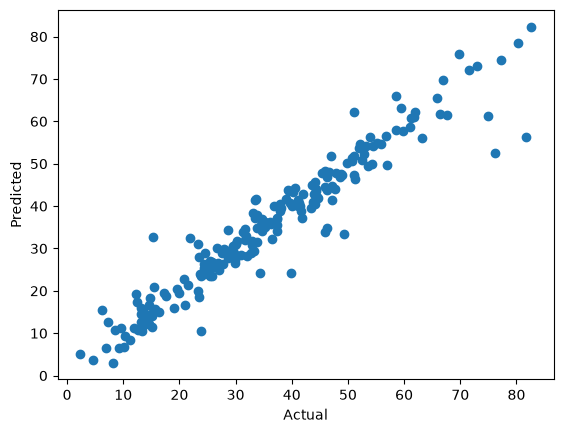

In [87]:
plt.scatter(y_test,y_pred);
plt.xlabel('Actual');
plt.ylabel('Predicted');

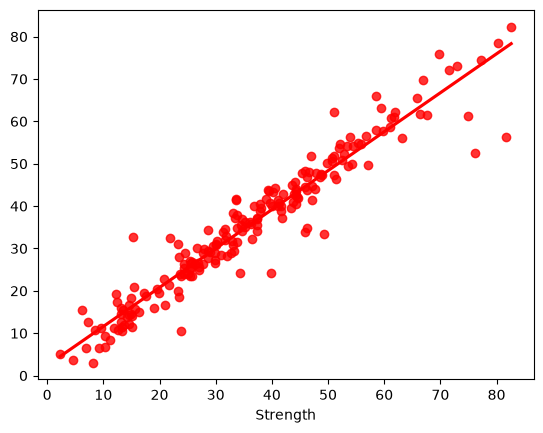

In [88]:
sns.regplot(x=y_test,y=y_pred,ci=None,color ='red');

In [89]:
pred_df=pd.DataFrame({'Actual Value':y_test,'Predicted Value':y_pred,'Difference':y_test-y_pred})
pred_df

,Actual Value,Predicted Value,Difference
951,19.01,15.885043,3.124957
654,24.29,24.055063,0.234937
706,26.32,26.267763,0.052237
538,34.57,35.483265,-0.913265
389,44.13,45.794189,-1.664189
...,...,...,...
232,50.77,51.371967,-0.601967
802,31.65,34.620411,-2.970411
358,66.95,69.764427,-2.814427
234,13.18,14.648232,-1.468232
